<a href="https://colab.research.google.com/github/Haiderabbas0080/slm-qa-finetuning/blob/main/qafinetune.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!nvidia-smi

Mon Nov  2 17:46:56 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   54C    P8             12W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
!pip install -q peft bitsandbytes accelerate datasets evaluate rouge_score bert_score kagglehub

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [4]:
from google.colab import userdata, drive
from huggingface_hub import login

login(userdata.get("HF_TOKEN"))
drive.mount("/content/drive")

Mounted at /content/drive


In [5]:
import os, gc, re, time, string, glob, collections
import torch, numpy as np, pandas as pd, evaluate
from datasets import Dataset
from sklearn.model_selection import train_test_split
from transformers import (AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig,
                          TrainingArguments, Trainer, set_seed)
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training

set_seed(42)
SAVE_DIR = "/content/drive/MyDrive/QA_FineTune"
os.makedirs(SAVE_DIR, exist_ok=True)
SYSTEM = "You are a helpful assistant that answers questions about artificial intelligence accurately and concisely."
MAX_LEN = 512

In [8]:
DATA_DIR = "/content/drive/MyDrive/QA_FineTune"
files = glob.glob(f"{DATA_DIR}/*.csv")
print("Mili hui files:", files)

df = pd.read_csv(files[0])
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
df.head()

Mili hui files: ['/content/drive/MyDrive/QA_FineTune/AI.csv']
Shape: (503, 2)
Columns: ['Question', 'Answer']


,Question,Answer
0,Who did the first work generally recognized as...,Warren McCulloch and Walter Pitts (1943).\n
1,What sources was drawn on the formation of the...,knowledge of the basic physiology and function...
2,Who created the Hebbian learning rule?,Donald Hebb (1949).\n
3,When the first neural network is built?,1950.\n
4,What is the first neural network called?,The SNARC.\n


In [10]:
q_col = next(c for c in df.columns if c.lower().startswith("q"))
a_col = next(c for c in df.columns if c.lower().startswith("a"))
df = df.rename(columns={q_col: "question", a_col: "answer"})[["question", "answer"]]

df = df.dropna()
for c in ["question", "answer"]:
    df[c] = df[c].astype(str).str.strip().str.replace(r"\s+", " ", regex=True)
df = df[(df.question.str.len() > 0) & (df.answer.str.len() > 0)]
df = df.drop_duplicates(subset="question").reset_index(drop=True)

train_df, temp_df = train_test_split(df, test_size=0.2, random_state=42)
val_df, test_df = train_test_split(temp_df, test_size=0.5, random_state=42)
print(f"Total: {len(df)} | Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")

words = train_df.answer.str.split().str.len()
print("Answer length (words): avg", round(words.mean(), 1), "| max", words.max())
MAX_NEW = int(min(256, np.percentile(words, 95) * 1.5 + 16))
print("Max new tokens for generation:", MAX_NEW)

Total: 502 | Train: 401 | Val: 50 | Test: 51
Answer length (words): avg 10.9 | max 37
Max new tokens for generation: 50


In [11]:
def make_prompt(tok, question):
    msgs = [{"role": "system", "content": SYSTEM}, {"role": "user", "content": question}]
    return tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)

def tokenize_df(tok, data):
    rows = []
    for q, a in zip(data["question"], data["answer"]):
        p_ids = tok(make_prompt(tok, q), add_special_tokens=False)["input_ids"]
        a_ids = tok(a + tok.eos_token, add_special_tokens=False)["input_ids"]
        rows.append({"input_ids": (p_ids + a_ids)[:MAX_LEN],
                     "labels": ([-100] * len(p_ids) + a_ids)[:MAX_LEN]})
    return Dataset.from_list(rows)

def make_collator(pad_id):
    def collate(batch):
        L = max(len(x["input_ids"]) for x in batch)
        return {
            "input_ids": torch.tensor([x["input_ids"] + [pad_id] * (L - len(x["input_ids"])) for x in batch]),
            "labels": torch.tensor([x["labels"] + [-100] * (L - len(x["labels"])) for x in batch]),
            "attention_mask": torch.tensor([[1] * len(x["input_ids"]) + [0] * (L - len(x["input_ids"])) for x in batch]),
        }
    return collate

@torch.no_grad()
def generate_answers(model, tok, questions, bs=8):
    tok.padding_side = "left"
    model.eval()
    model.config.use_cache = True
    outs = []
    for i in range(0, len(questions), bs):
        prompts = [make_prompt(tok, q) for q in questions[i:i + bs]]
        enc = tok(prompts, return_tensors="pt", padding=True, add_special_tokens=False).to(model.device)
        gen = model.generate(**enc, max_new_tokens=MAX_NEW, do_sample=False, pad_token_id=tok.pad_token_id)
        for g in gen:
            outs.append(tok.decode(g[enc["input_ids"].shape[1]:], skip_special_tokens=True).strip())
    tok.padding_side = "right"
    return outs

def normalize(s):
    s = s.lower()
    s = "".join(ch for ch in s if ch not in set(string.punctuation))
    s = re.sub(r"\b(a|an|the)\b", " ", s)
    return " ".join(s.split())

def token_f1(pred, ref):
    p, r = normalize(pred).split(), normalize(ref).split()
    same = sum((collections.Counter(p) & collections.Counter(r)).values())
    if same == 0:
        return 0.0
    prec, rec = same / len(p), same / len(r)
    return 2 * prec * rec / (prec + rec)

rouge = evaluate.load("rouge")
bertscore = evaluate.load("bertscore")

def compute_metrics(preds, refs):
    return {
        "EM": round(np.mean([normalize(p) == normalize(r) for p, r in zip(preds, refs)]) * 100, 2),
        "F1": round(np.mean([token_f1(p, r) for p, r in zip(preds, refs)]) * 100, 2),
        "ROUGE-L": round(rouge.compute(predictions=preds, references=refs)["rougeL"] * 100, 2),
        "BERTScore": round(np.mean(bertscore.compute(predictions=preds, references=refs, lang="en")["f1"]) * 100, 2),
    }

print("Step 7 done ✅")

Step 7 done ✅


In [14]:
def run_experiment(model_name, short):
    torch.cuda.reset_peak_memory_stats()
    tok = AutoTokenizer.from_pretrained(model_name)
    if tok.pad_token is None:
        tok.pad_token = tok.eos_token
    tok.padding_side = "right"

    bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                             bnb_4bit_compute_dtype=torch.float16, bnb_4bit_use_double_quant=True)
    model = AutoModelForCausalLM.from_pretrained(model_name, quantization_config=bnb, device_map="auto")

    questions = test_df["question"].tolist()
    print("1) Base model (bina fine-tuning) ke answers...")
    base_preds = generate_answers(model, tok, questions)

    model = prepare_model_for_kbit_training(model, use_gradient_checkpointing=True)
    model = get_peft_model(model, LoraConfig(
        r=16, lora_alpha=32, lora_dropout=0.05, task_type="CAUSAL_LM",
        target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]))
    model.print_trainable_parameters()
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)

    args = TrainingArguments(
        output_dir=f"/content/{short}_out", num_train_epochs=3,
        per_device_train_batch_size=4, per_device_eval_batch_size=4, gradient_accumulation_steps=4,
        learning_rate=2e-4, lr_scheduler_type="cosine", warmup_steps=4,
        logging_steps=5, eval_strategy="epoch", save_strategy="epoch",
        load_best_model_at_end=True, metric_for_best_model="eval_loss", save_total_limit=1,
        fp16=True, gradient_checkpointing=True, gradient_checkpointing_kwargs={"use_reentrant": False},
        remove_unused_columns=False, report_to="none", seed=42)

    trainer = Trainer(model=model, args=args,
                      train_dataset=tokenize_df(tok, train_df), eval_dataset=tokenize_df(tok, val_df),
                      data_collator=make_collator(tok.pad_token_id))
    model.config.use_cache = False
    print("2) Training shuru...")
    t0 = time.time()
    trainer.train()
    train_time = (time.time() - t0) / 60

    print("3) Fine-tuned model ke answers...")
    ft_preds = generate_answers(model, tok, questions)

    model.save_pretrained(f"{SAVE_DIR}/{short}_lora")
    pd.DataFrame({"question": questions, "reference": test_df["answer"].tolist(),
                  "base": base_preds, "finetuned": ft_preds}).to_csv(f"{SAVE_DIR}/{short}_predictions.csv", index=False)

    info = {"log_history": trainer.state.log_history, "train_time_min": train_time,
            "trainable_params": trainable, "peak_gpu_gb": torch.cuda.max_memory_allocated() / 1e9}
    del model, trainer
    gc.collect(); torch.cuda.empty_cache()
    return base_preds, ft_preds, info

print("Step 8 done ✅")

Step 8 done ✅


In [15]:
qwen_base, qwen_ft, qwen_info = run_experiment("Qwen/Qwen2.5-0.5B-Instruct", "qwen")

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

1) Base model (bina fine-tuning) ke answers...
trainable params: 8,798,208 || all params: 502,830,976 || trainable%: 1.7497
2) Training shuru...


Epoch,Training Loss,Validation Loss
1,2.823138,2.648594
2,2.016755,2.631495
3,1.624462,2.665143


3) Fine-tuned model ke answers...


In [16]:
llama_base, llama_ft, llama_info = run_experiment("meta-llama/Llama-3.2-1B-Instruct", "llama")

config.json:   0%|          | 0.00/877 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/54.5k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.09M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/296 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.47GB            

model.safetensors: downloading bytes:           |  0.00B            

... (3 outputs left out)

[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


trainable params: 11,272,192 || all params: 1,247,086,592 || trainable%: 0.9039
2) Training shuru...


Epoch,Training Loss,Validation Loss
1,2.816797,2.590545
2,1.944343,2.593484
3,1.590943,2.652428


3) Fine-tuned model ke answers...


In [17]:
refs = test_df["answer"].tolist()
rows = []
for name, base, ft, info in [("Qwen2.5-0.5B", qwen_base, qwen_ft, qwen_info),
                             ("Llama-3.2-1B", llama_base, llama_ft, llama_info)]:
    rows.append({"Model": name, "Version": "Base", **compute_metrics(base, refs)})
    rows.append({"Model": name, "Version": "Fine-tuned (QLoRA)", **compute_metrics(ft, refs),
                 "Train time (min)": round(info["train_time_min"], 1),
                 "Trainable params": info["trainable_params"],
                 "Peak GPU (GB)": round(info["peak_gpu_gb"], 2)})
results = pd.DataFrame(rows)
results.to_csv(f"{SAVE_DIR}/results.csv", index=False)
results

config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.42GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


,Model,Version,EM,F1,ROUGE-L,BERTScore,Train time (min),Trainable params,Peak GPU (GB)
0,Qwen2.5-0.5B,Base,0.0,12.36,13.48,85.16,NaN,NaN,NaN
1,Qwen2.5-0.5B,Fine-tuned (QLoRA),0.0,14.17,16.81,87.78,3.2,8798208.0,2.59
2,Llama-3.2-1B,Base,0.0,11.97,12.82,84.81,NaN,NaN,NaN
3,Llama-3.2-1B,Fine-tuned (QLoRA),0.0,17.57,19.83,88.08,2.3,11272192.0,3.77


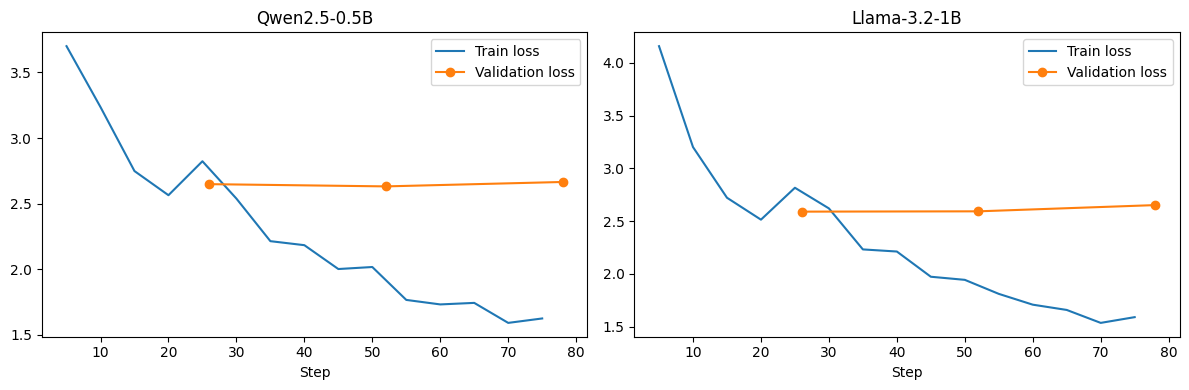

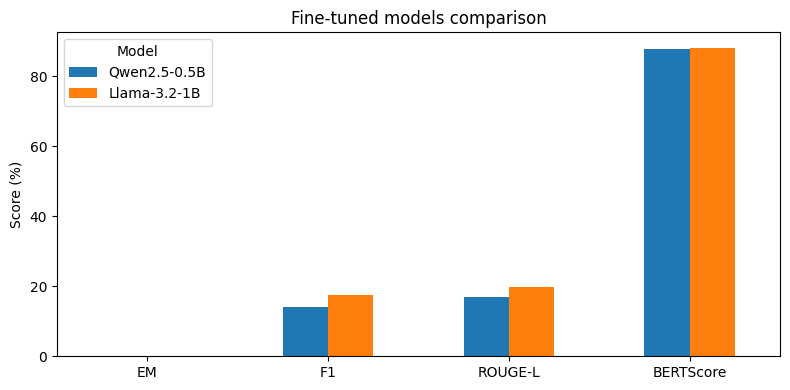

Q: What is the example of games with Type B strategy

REFERENCE: Most of the Go programs are more often Type B strategy.

QWEN: "Go Fish

LLAMA: The game of chess
Q: What is the mean for Ford (2018) interviews of AI experts in the question of when (if ever) will AI systems achieve human-level performance across a broad variety of tasks?

REFERENCE: 2099

QWEN: "3 years from now."

LLAMA: "Within the next 20 years
Q: What does the forward chaining apply to?

REFERENCE: "It is suitable for the planning

QWEN: Forward chaining applies to inference from sentences in a knowledge base.

LLAMA: The forward chaining applies to the forward chaining


In [18]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for i, (name, info) in enumerate([("Qwen2.5-0.5B", qwen_info), ("Llama-3.2-1B", llama_info)]):
    tr = [(l["step"], l["loss"]) for l in info["log_history"] if "loss" in l]
    ev = [(l["step"], l["eval_loss"]) for l in info["log_history"] if "eval_loss" in l]
    if tr: ax[i].plot(*zip(*tr), label="Train loss")
    if ev: ax[i].plot(*zip(*ev), marker="o", label="Validation loss")
    ax[i].set_title(name); ax[i].set_xlabel("Step"); ax[i].legend()
plt.tight_layout(); plt.savefig(f"{SAVE_DIR}/loss_curves.png"); plt.show()

ft = results[results.Version == "Fine-tuned (QLoRA)"].set_index("Model")[["EM", "F1", "ROUGE-L", "BERTScore"]]
ft.T.plot(kind="bar", figsize=(8, 4), title="Fine-tuned models comparison", rot=0)
plt.ylabel("Score (%)"); plt.tight_layout(); plt.savefig(f"{SAVE_DIR}/metrics_comparison.png"); plt.show()

for i in range(3):
    print("=" * 90)
    print("Q:", test_df.iloc[i]["question"])
    print("\nREFERENCE:", refs[i])
    print("\nQWEN:", qwen_ft[i])
    print("\nLLAMA:", llama_ft[i])